# Project A: Can a topological edge survive strong interactions?

Interacting SSH chain of spinless fermions, open boundaries, half filling $N = L/2$:

$$
H = -\sum_{j=0}^{L-2} J_j \left(c_j^\dagger c_{j+1} + \text{h.c.}\right) + V \sum_{j=0}^{L-2} \left(n_j - \tfrac{1}{2}\right)\left(n_{j+1} - \tfrac{1}{2}\right), \qquad J_j = 1 + (-1)^j \delta
$$

**Conventions.** $\hbar = J = 1$, sites $j = 0,\dots,L-1$, bond $j$ joins sites $j$ and $j+1$.
$\delta < 0$ means the chain starts on a weak bond: $J_0 = J_w = 1 - |\delta|$, $J_s = 1 + |\delta|$, $r = J_w/J_s$.
Entropies in nats.

**How to run.** Select the `qiskit-env` kernel and run all cells top to bottom.
Each step has a parameter cell at its start. Figures are saved as PDF in `figures/` for the LaTeX report (`report.tex`).
Every check prints `[pass]` or `[FAIL]`; the summary at the end of each step counts them.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mpmath
import numpy as np
import pandas as pd
from IPython.display import display

SAVE_FIGS = True
FIG_DIR = Path("figures")  # upload this folder to Overleaf together with report.tex
FIG_DIR.mkdir(exist_ok=True)

# Plot style: serif to match LaTeX; colours keyed to |delta|
COLORS = {0.15: "#2a78d6", 0.30: "#eb6834", 0.50: "#1baf7a"}
GRAY, LIGHT = "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "serif", "mathtext.fontset": "cm", "font.size": 9,
    "axes.grid": True, "grid.color": LIGHT, "grid.linewidth": 0.6,
    "axes.edgecolor": GRAY, "axes.linewidth": 0.8,
    "legend.frameon": False, "lines.linewidth": 1.5, "lines.markersize": 4.5,
    "figure.dpi": 120,
})
pd.set_option("display.float_format", lambda x: f"{x:.6g}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)


def savefig(fig, name):
    if SAVE_FIGS:
        path = FIG_DIR / f"{name}.pdf"
        fig.savefig(path, bbox_inches="tight")
        print(f"saved {path}")


CHECKS = {}  # keyed by name, so re-running a cell does not count its checks twice


def check(name, passed, value=None):
    """Record and print one validation check."""
    CHECKS[name] = {"pass": bool(passed), "value": value}
    tail = "" if value is None else f"   [{value:.2e}]"
    print(f"[{'pass' if passed else 'FAIL'}] {name}{tail}")

---
## Step 1. The free edge problem ($V = 0$)

At $V=0$ the Hamiltonian is quadratic, $H_0 = \sum_{ij} c_i^\dagger h_{ij} c_j$ with $h_{j,j+1} = h_{j+1,j} = -J_j$,
so everything follows from the $L\times L$ hopping matrix $h$.

Analytic results (derived in `report.tex`, Sec. 2):
* zero mode on the even sites, $\psi_{2\ell} = \sqrt{1-r^2}\,(-r)^\ell$, with $|\psi_j|^2 \propto e^{-2j/\xi}$ and $\xi = 2/\ln(J_s/J_w)$;
* end-pair splitting on a finite chain, $\Delta E \simeq 2J_s(1-r^2)\,e^{-L/\xi}$;
* ring bands $E_\pm(k) = \pm\sqrt{J_w^2 + J_s^2 + 2J_wJ_s\cos k}$, with gap $4|\delta|$ and addition cost $2|\delta|$.

In [2]:
# ---- Step 1 parameters (edit these) ----
L_LIST = [40, 80, 120]                               # open-chain lengths
DELTA_LIST = [-0.50, -0.30, -0.15, 0.15, 0.30, 0.50]   # dimerisation (delta < 0: weak end bonds)
N_FIT_LIST = [6, 8, 10]                              # number of even sites used in the xi fit
L_SCAN = list(range(12, 121, 4))                     # lengths for the splitting-vs-L plot
L_EX, DELTA_EX = 40, -0.30                           # example used in the spectrum / end-pair plots
L_PROFILE = 80                                       # length used for the edge-profile plot
XI_GUIDE = 3.230813126                               # guide value of xi at delta = -0.30
L_ODD_M = [18, 42, 62, 82]                           # open chains with odd M = L/2, so s = -1
L_RING_ODD = [10, 14, 18]                            # rings with odd M (the Step 6 sizes)

### 1.1 Functions

In [3]:
def bonds(L, delta, periodic=False):
    """J_j = 1 + (-1)^j delta for the L-1 bonds of an open chain (L bonds on a ring)."""
    j = np.arange(L if periodic else L - 1)
    return 1.0 + (-1.0) ** j * delta


def hopping_matrix(L, delta, periodic=False):
    """One-particle matrix h with h[j, j+1] = h[j+1, j] = -J_j."""
    h = np.zeros((L, L))
    for j, Jj in enumerate(bonds(L, delta, periodic)):
        k = (j + 1) % L
        h[j, k] = h[k, j] = -Jj
    return h


def weak_strong(delta):
    return 1.0 - abs(delta), 1.0 + abs(delta)


def ratio(delta):
    J_w, J_s = weak_strong(delta)
    return J_w / J_s


def xi_exact(delta):
    """Amplitude localisation length xi = 2 / ln(J_s / J_w)."""
    J_w, J_s = weak_strong(delta)
    return 2.0 / np.log(J_s / J_w)


def zero_mode(L, delta):
    """Analytic left zero mode psi_{2l} = sqrt(1 - r^2) (-r)^l, truncated to L sites (delta < 0)."""
    r = ratio(delta)
    psi = np.zeros(L)
    psi[0::2] = np.sqrt(1 - r**2) * (-r) ** np.arange(L // 2)
    return psi


def edge_pair(L, delta):
    """Diagonalise h; separate the two states nearest E = 0 into left/right edge states.

    left/right: eigenvectors of the position operator X inside the pair subspace.
    left_chiral: same, using the chiral operator Gamma = diag((-1)^j) (independent route).
    bonding/antibonding: state-selection convention for half filling,
        phi_-+ = (psi_L -+ s psi_R)/sqrt(2), s = sgn t = (-1)^(L/2), t = <psi_L|h|psi_R>,
    with signs fixed by psi_L(0) > 0 and psi_R(L-1) > 0.
    """
    h = hopping_matrix(L, delta)
    E, U = np.linalg.eigh(h)
    pair = np.sort(np.argsort(np.abs(E))[:2])
    P = U[:, pair]

    _, vx = np.linalg.eigh(P.T @ np.diag(np.arange(L, dtype=float)) @ P)
    left, right = P @ vx[:, 0], P @ vx[:, 1]
    _, vg = np.linalg.eigh(P.T @ np.diag((-1.0) ** np.arange(L)) @ P)
    left_chiral = P @ vg[:, 1]

    left, right = left * np.sign(left[0]), right * np.sign(right[-1])
    left_chiral = left_chiral * np.sign(left_chiral[0])
    s = (-1) ** (L // 2)
    return dict(E=E, U=U, pair=pair, left=left, right=right, left_chiral=left_chiral,
                t=left @ h @ right, s=s,
                bonding=(left - s * right) / np.sqrt(2), antibonding=(left + s * right) / np.sqrt(2))


def fit_xi(prob, n_fit):
    """Fit |psi_j|^2 = A exp(-2 j / xi) on the first n_fit even sites; return xi."""
    j = 2 * np.arange(n_fit)
    slope = np.polyfit(j, np.log(prob[j]), 1)[0]
    return -2.0 / slope


def splitting_asym(L, delta):
    """Leading-order splitting 2 J_s (1 - r^2) r^(L/2)."""
    _, J_s = weak_strong(delta)
    r = ratio(delta)
    return 2 * J_s * (1 - r**2) * r ** (L // 2)


def splitting_sturm(L, delta, dps=80):
    """Exact splitting 2*eps_0 in 80-digit arithmetic (independent of numpy).

    Sturm count: the number of negative pivots q_j of h - x equals the number of eigenvalues
    below x, with q_0 = -x, q_j = -x - J_{j-1}^2 / q_{j-1}.  Bisect (in ln x) for the
    smallest positive eigenvalue eps_0, where the count steps from L/2 to L/2 + 1.
    """
    with mpmath.workdps(dps):
        J2 = [(1 + (-1) ** j * mpmath.mpf(delta)) ** 2 for j in range(L - 1)]
        tiny = mpmath.mpf(10) ** (-2 * dps)

        def count_below(x):
            q, n = -x, int(x > 0)
            for b in J2:
                q = -x - b / (q if q != 0 else tiny)
                n += int(q < 0)
            return n

        lo, hi = mpmath.mpf(10) ** (-dps + 10), mpmath.mpf(abs(delta))
        assert count_below(lo) == L // 2 and count_below(hi) == L // 2 + 1
        while hi / lo - 1 > mpmath.mpf(10) ** -30:
            mid = mpmath.sqrt(lo * hi)
            lo, hi = (mid, hi) if count_below(mid) == L // 2 else (lo, mid)
        return float(2 * lo)


def bloch_bands(k, delta):
    """E_pm(k) = pm sqrt(J_0^2 + J_1^2 + 2 J_0 J_1 cos k), two sites per cell."""
    J0, J1 = 1 + delta, 1 - delta
    e = np.sqrt(J0**2 + J1**2 + 2 * J0 * J1 * np.cos(k))
    return -e, e

### 1.2 Basic checks of the Hamiltonian and the analytic zero mode

In [4]:
for delta in [d for d in DELTA_LIST if d < 0]:
    J = bonds(40, delta)
    check(f"delta={delta:+.2f}: J_0 = J_w and J_(L-2) = J_0", J[0] == weak_strong(delta)[0] and J[-1] == J[0])

check("h is symmetric", all(np.array_equal(hopping_matrix(L, d), hopping_matrix(L, d).T)
                            for L in L_LIST for d in DELTA_LIST))

dev = max(np.max(np.abs(np.sort(E) + np.sort(E)[::-1]))
          for L in L_LIST for d in DELTA_LIST for E in [np.linalg.eigvalsh(hopping_matrix(L, d))])
check("chiral symmetry: spectrum symmetric under E -> -E", dev < 1e-12, dev)

check("xi(-0.30) = 3.230813126 (guide)", abs(xi_exact(-0.30) - XI_GUIDE) < 1e-9, abs(xi_exact(-0.30) - XI_GUIDE))

# The truncated zero mode solves h psi = 0 on every row except the last: (h psi)_{L-1} = -J_w psi_{L-2}
res = 0.0
for L in L_LIST:
    for delta in [d for d in DELTA_LIST if d < 0]:
        psi = zero_mode(L, delta)
        hpsi = hopping_matrix(L, delta) @ psi
        res = max(res, np.max(np.abs(hpsi[:-1])), abs(hpsi[-1] + weak_strong(delta)[0] * psi[-2]))
check("analytic zero mode: h psi = 0 except last row", res < 1e-12, res)

for d in sorted({abs(d) for d in DELTA_LIST}):
    print(f"|delta| = {d:.2f}:  r = {ratio(d):.6f},  1 - r^2 = {1 - ratio(d)**2:.6f},  xi = {xi_exact(d):.9f}")

[pass] delta=-0.50: J_0 = J_w and J_(L-2) = J_0
[pass] delta=-0.30: J_0 = J_w and J_(L-2) = J_0
[pass] delta=-0.15: J_0 = J_w and J_(L-2) = J_0
[pass] h is symmetric
[pass] chiral symmetry: spectrum symmetric under E -> -E   [2.44e-15]
[pass] xi(-0.30) = 3.230813126 (guide)   [4.44e-11]
[pass] analytic zero mode: h psi = 0 except last row   [5.55e-17]
|delta| = 0.15:  r = 0.739130,  1 - r^2 = 0.453686,  xi = 6.616363079
|delta| = 0.30:  r = 0.538462,  1 - r^2 = 0.710059,  xi = 3.230813126
|delta| = 0.50:  r = 0.333333,  1 - r^2 = 0.888889,  xi = 1.820478453


### 1.3 Spectrum: an end pair appears only for weak end bonds

,L,delta,states with |E| < |delta|,min|E| / (2|delta|)
0,40,-0.5,2,3.82396e-10
1,40,-0.3,2,6.45922e-06
2,40,-0.15,2,0.00411884
3,40,0.15,0,1.09156
4,40,0.3,0,1.02509
5,40,0.5,0,1.00796
6,80,-0.5,2,3.31282e-17
7,80,-0.3,2,2.71185e-11
8,80,-0.15,2,9.75384e-06
9,80,0.15,0,1.02758


[pass] delta < 0: exactly two in-gap states
[pass] delta > 0: no in-gap states (reversing delta removes the end pair)
[pass] delta > 0: lowest |E| is at the bulk edge, >= 2|delta|
saved figures/step1_spectrum.pdf


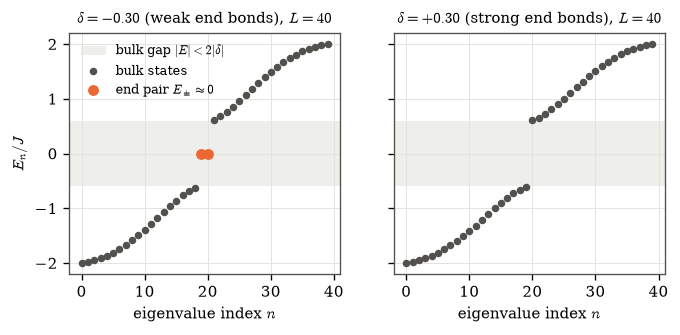

In [5]:
rows = []
for L in L_LIST:
    for delta in DELTA_LIST:
        E = np.linalg.eigvalsh(hopping_matrix(L, delta))
        rows.append({"L": L, "delta": delta, "states with |E| < |delta|": int(np.sum(np.abs(E) < abs(delta))),
                     "min|E| / (2|delta|)": np.min(np.abs(E)) / (2 * abs(delta))})
spec = pd.DataFrame(rows)
display(spec)

check("delta < 0: exactly two in-gap states", all(spec[spec.delta < 0]["states with |E| < |delta|"] == 2))
check("delta > 0: no in-gap states (reversing delta removes the end pair)",
      all(spec[spec.delta > 0]["states with |E| < |delta|"] == 0))
check("delta > 0: lowest |E| is at the bulk edge, >= 2|delta|",
      all(spec[spec.delta > 0]["min|E| / (2|delta|)"] >= 1 - 1e-12))

fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.6), sharey=True)
for ax, delta in zip(axes, (DELTA_EX, -DELTA_EX)):
    E = np.linalg.eigvalsh(hopping_matrix(L_EX, delta))
    n, edge = np.arange(L_EX), np.abs(E) < abs(delta)
    ax.axhspan(-2 * abs(delta), 2 * abs(delta), color=LIGHT, alpha=0.6, lw=0, label=r"bulk gap $|E|<2|\delta|$")
    ax.plot(n[~edge], E[~edge], "o", color=GRAY, ms=3.5, label="bulk states")
    if edge.any():
        ax.plot(n[edge], E[edge], "o", color=COLORS[abs(delta)], ms=5.5, label=r"end pair $E_\pm\approx0$")
    ax.set_title(rf"$\delta={delta:+.2f}$ ({'weak' if delta < 0 else 'strong'} end bonds), $L={L_EX}$", fontsize=9)
    ax.set_xlabel("eigenvalue index $n$")
axes[0].set_ylabel("$E_n/J$")
axes[0].legend(loc="upper left", fontsize=7.5)
savefig(fig, "step1_spectrum")
plt.show()

### 1.4 Edge states and the localisation length

On a finite chain the two states nearest zero ($\psi_\pm$) are spread over **both** ends.
Diagonalising the position operator $X$ inside their 2D subspace gives the left- and right-localised states.
We fit $\ln|\psi_j|^2$ against $j$ on the first `n_fit` even sites (slope $-2/\xi$).

In [6]:
EDGE = {(L, d): edge_pair(L, d) for L in L_LIST for d in DELTA_LIST if d < 0}

rows = []
for (L, delta), ep in EDGE.items():
    row = {"delta": delta, "L": L, "xi exact": xi_exact(delta)}
    for n in N_FIT_LIST:
        row[f"rel err (n_fit={n})"] = (fit_xi(ep["left"] ** 2, n) - xi_exact(delta)) / xi_exact(delta)
    row[f"xi fit (n_fit={N_FIT_LIST[-1]})"] = fit_xi(ep["left"] ** 2, N_FIT_LIST[-1])
    rows.append(row)
xi_table = pd.DataFrame(rows).sort_values(["delta", "L"], ascending=[False, True])
display(xi_table)

err_cols = [c for c in xi_table if c.startswith("rel err")]
worst = xi_table[err_cols].abs().to_numpy().max()
check("fitted xi = 2/ln(J_s/J_w) for all L, delta, n_fit (tol 1e-3)", worst < 1e-3, worst)
worst_guide = xi_table[xi_table.delta == -0.30][err_cols].abs().to_numpy().max()
check("fitted xi at delta = -0.30 matches guide value", worst_guide < 1e-3, worst_guide)

odd = max(np.sum(ep["left"][1::2] ** 2) for ep in EDGE.values())
check("left edge state has no weight on odd sites", odd < 1e-12, odd)
dev = max(1 - (ep["left"] @ ep["left_chiral"]) ** 2 for ep in EDGE.values())
check("left state from X equals left state from chiral Gamma", abs(dev) < 1e-12, abs(dev))

,delta,L,xi exact,rel err (n_fit=6),rel err (n_fit=8),rel err (n_fit=10),xi fit (n_fit=10)
2,-0.15,40,6.61636,-5.98194e-05,-0.000148542,-0.000370362,6.61391
5,-0.15,80,6.61636,-3.35468e-10,-8.33018e-10,-2.07672e-09,6.61636
8,-0.15,120,6.61636,-1.47664e-15,-4.83263e-15,-1.235e-14,6.61636
1,-0.3,40,3.23081,-2.32166e-09,-1.71188e-08,-1.37333e-07,3.23081
4,-0.3,80,3.23081,0,1.64945e-15,2.61163e-15,3.23081
7,-0.3,120,3.23081,1.37454e-15,1.37454e-16,-4.12363e-16,3.23081
0,-0.5,40,1.82048,-2.43941e-16,-3.23222e-14,-1.73052e-12,1.82048
3,-0.5,80,1.82048,3.65911e-16,2.43941e-16,2.43941e-16,1.82048
6,-0.5,120,1.82048,0,-2.43941e-16,0,1.82048


[pass] fitted xi = 2/ln(J_s/J_w) for all L, delta, n_fit (tol 1e-3)   [3.70e-04]
[pass] fitted xi at delta = -0.30 matches guide value   [1.37e-07]
[pass] left edge state has no weight on odd sites   [2.36e-29]
[pass] left state from X equals left state from chiral Gamma   [5.77e-15]


saved figures/step1_edge_states.pdf


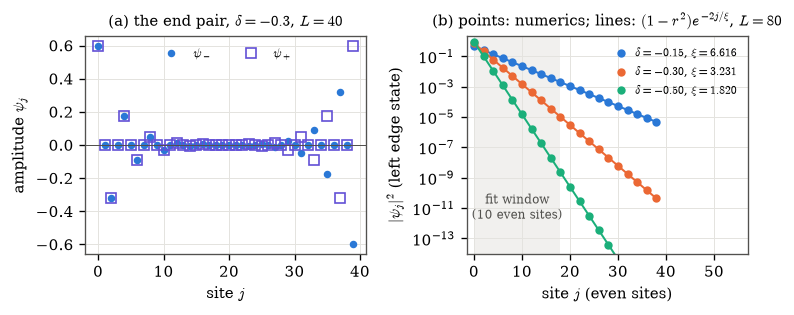

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.7))

ax = axes[0]
ep = EDGE[(L_EX, DELTA_EX)]
j = np.arange(L_EX)
for i, (lab, c, mk) in enumerate([(r"$\psi_-$", "#2a78d6", "o"), (r"$\psi_+$", "#6250d6", "s")]):
    col = ep["U"][:, ep["pair"][i]]
    col = col * np.sign(col[0])
    ax.plot(j, col, mk, color=c, ms=3.5 if mk == "o" else 6, mfc=c if mk == "o" else "none", label=lab)
ax.axhline(0, color=GRAY, lw=0.6)
ax.set_xlabel("site $j$")
ax.set_ylabel(r"amplitude $\psi_j$")
ax.set_title(rf"(a) the end pair, $\delta={DELTA_EX}$, $L={L_EX}$", fontsize=9)
ax.legend(loc="upper center", fontsize=7.5, ncol=2)

ax = axes[1]
even = np.arange(0, 40, 2)
for delta in sorted({d for d in DELTA_LIST if d < 0}, reverse=True):
    c = COLORS[abs(delta)]
    xi, r = xi_exact(delta), ratio(delta)
    ax.semilogy(even, (1 - r**2) * np.exp(-2 * even / xi), "-", color=c, lw=1.2)
    ax.semilogy(even, EDGE[(L_PROFILE, delta)]["left"][even] ** 2, "o", color=c, ms=4,
                label=rf"$\delta={delta:+.2f}$, $\xi={xi:.3f}$")
ax.axvspan(0, 2 * (N_FIT_LIST[-1] - 1), color=LIGHT, alpha=0.5, lw=0)
ax.text(N_FIT_LIST[-1] - 1, 2e-12, f"fit window\n({N_FIT_LIST[-1]} even sites)", ha="center", fontsize=7, color=GRAY)
ax.set_ylim(1e-14, 2)
ax.set_xlim(-1.5, 57)  # empty strip on the right holds the legend
ax.set_xlabel("site $j$ (even sites)")
ax.set_ylabel(r"$|\psi_j|^2$ (left edge state)")
ax.set_title(rf"(b) points: numerics; lines: $(1-r^2)e^{{-2j/\xi}}$, $L={L_PROFILE}$", fontsize=9)
ax.legend(loc="upper right", fontsize=7, handletextpad=0.2)
fig.tight_layout()
savefig(fig, "step1_edge_states")
plt.show()

### 1.5 End-pair splitting versus $L$

Three routes: dense `eigh` (limited by round-off), an exact 80-digit Sturm bisection (mpmath),
and the analytic leading order $2J_s(1-r^2)e^{-L/\xi}$. The slope of $\ln\Delta E$ against $L$ must be $-1/\xi$.

In [8]:
rows = []
for delta in sorted({d for d in DELTA_LIST if d < 0}):
    for L in sorted(set(L_SCAN) | set(L_LIST)):
        E = np.linalg.eigvalsh(hopping_matrix(L, delta))
        pair = np.sort(E[np.argsort(np.abs(E))[:2]])
        rows.append({"delta": delta, "L": L, "dE eigh": pair[1] - pair[0],
                     "dE exact (Sturm)": splitting_sturm(L, delta), "dE asymptotic": splitting_asym(L, delta)})
split = pd.DataFrame(rows)
split["asym/exact - 1"] = split["dE asymptotic"] / split["dE exact (Sturm)"] - 1
split["eigh/exact - 1"] = split["dE eigh"] / split["dE exact (Sturm)"] - 1
display(split[split.L.isin(L_LIST)])

for delta in sorted({d for d in DELTA_LIST if d < 0}):
    s = split[split.delta == delta]
    check(f"delta={delta:+.2f}: splitting decreases with L", np.all(np.diff(s["dE exact (Sturm)"]) < 0))
    big = s[s.L >= 40]
    slope = np.polyfit(big.L, np.log(big["dE exact (Sturm)"]), 1)[0]
    print(f"    slope of ln(dE) vs L (L >= 40) = {slope:.6f},  -1/xi = {-1 / xi_exact(delta):.6f}")
    check(f"delta={delta:+.2f}: slope = -1/xi", abs(slope * xi_exact(delta) + 1) < 1e-3,
          abs(slope * xi_exact(delta) + 1))
worst = split.loc[split.L >= 40, "asym/exact - 1"].abs().max()
check("asymptotic formula vs exact splitting (L >= 40, tol 1e-4)", worst < 1e-4, worst)

,delta,L,dE eigh,dE exact (Sturm),dE asymptotic,asym/exact - 1,eigh/exact - 1
7,-0.5,40,7.64793e-10,7.64793e-10,7.64793e-10,-1.22125e-15,-4.6062e-12
17,-0.5,80,1.21143e-16,2.1934e-19,2.1934e-19,-2.44249e-15,551.305
27,-0.5,120,9.62591e-17,6.29062e-29,6.29062e-29,-3.33067e-15,1.5302e+12
35,-0.3,40,7.75107e-06,7.75107e-06,7.75107e-06,-2.4522e-10,1.86517e-14
45,-0.3,80,3.25428e-11,3.25428e-11,3.25428e-11,-2.55351e-15,5.28704e-10
55,-0.3,120,8.59915e-16,1.36631e-16,1.36631e-16,-4.10783e-15,5.29371
63,-0.15,40,0.0024713,0.0024713,0.00247118,-4.78292e-05,-2.87548e-14
73,-0.15,80,5.8523e-06,5.8523e-06,5.8523e-06,-5.53637e-10,-4.70735e-14
83,-0.15,120,1.38595e-08,1.38595e-08,1.38595e-08,-4.44089e-16,-1.6831e-13


[pass] delta=-0.50: splitting decreases with L
    slope of ln(dE) vs L (L >= 40) = -0.549306,  -1/xi = -0.549306
[pass] delta=-0.50: slope = -1/xi   [2.22e-16]
[pass] delta=-0.30: splitting decreases with L
    slope of ln(dE) vs L (L >= 40) = -0.309520,  -1/xi = -0.309520
[pass] delta=-0.30: slope = -1/xi   [2.81e-12]
[pass] delta=-0.15: splitting decreases with L
    slope of ln(dE) vs L (L >= 40) = -0.151141,  -1/xi = -0.151140
[pass] delta=-0.15: slope = -1/xi   [1.46e-06]
[pass] asymptotic formula vs exact splitting (L >= 40, tol 1e-4)   [4.78e-05]


saved figures/step1_splitting.pdf


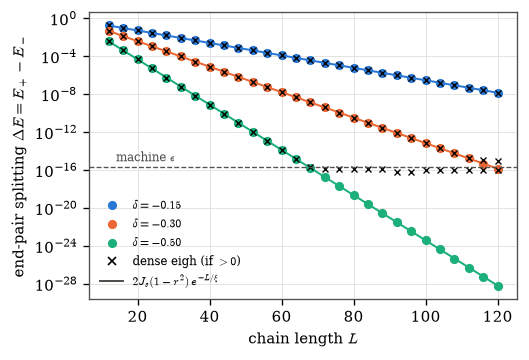

In [9]:
fig, ax = plt.subplots(figsize=(4.6, 3.1))
for delta in sorted({d for d in DELTA_LIST if d < 0}, reverse=True):
    c, s = COLORS[abs(delta)], split[(split.delta == delta) & split.L.isin(L_SCAN)]
    ax.semilogy(s.L, s["dE asymptotic"], "-", color=c, lw=1.2)
    ax.semilogy(s.L, s["dE exact (Sturm)"], "o", color=c, ms=4.5, label=rf"$\delta={delta:+.2f}$")
    ok = s["dE eigh"] > 0
    ax.semilogy(s.L[ok], s["dE eigh"][ok], "x", color="k", ms=4, mew=0.8)
ax.axhline(np.finfo(float).eps, color=GRAY, lw=0.8, ls="--")
ax.text(14, 4e-16, r"machine $\epsilon$", fontsize=7, color=GRAY, va="bottom")
ax.plot([], [], "x", color="k", label="dense eigh (if $>0$)")
ax.plot([], [], "-", color=GRAY, lw=1.2, label=r"$2J_s(1-r^2)\,e^{-L/\xi}$")
ax.set_xlabel("chain length $L$")
ax.set_ylabel(r"end-pair splitting $\Delta E = E_+ - E_-$")
ax.legend(fontsize=7, loc="lower left")
savefig(fig, "step1_splitting")
plt.show()

### 1.6 Bulk bands on a ring

Ring of $M = L/2$ two-site cells, $k = 2\pi m/M$. The spectrum must equal $E_\pm(k)$, the gap must be $4|\delta|$
(when $M$ is even so that $k=\pi$ is allowed) and the bulk addition cost $2|\delta|$. The bands are identical for $\pm\delta$.

In [10]:
rows = []
for L in L_LIST:
    k = 2 * np.pi * np.arange(L // 2) / (L // 2)
    for delta in DELTA_LIST:
        E = np.sort(np.linalg.eigvalsh(hopping_matrix(L, delta, periodic=True)))
        E_bloch = np.sort(np.concatenate(bloch_bands(k, delta)))
        E_flip = np.sort(np.linalg.eigvalsh(hopping_matrix(L, -delta, periodic=True)))
        rows.append({"L": L, "delta": delta, "max|E - E_bloch|": np.max(np.abs(E - E_bloch)),
                     "gap": 2 * E[E > 0].min(), "4|delta|": 4 * abs(delta),
                     "addition cost": E[E > 0].min(), "max|E(delta) - E(-delta)|": np.max(np.abs(E - E_flip))})
ring = pd.DataFrame(rows)
display(ring)

check("ring spectrum = Bloch bands", ring["max|E - E_bloch|"].max() < 1e-12, ring["max|E - E_bloch|"].max())
check("ring gap = 4|delta|", np.max(np.abs(ring.gap - ring["4|delta|"])) < 1e-12, np.max(np.abs(ring.gap - ring["4|delta|"])))
check("bulk addition cost = 2|delta|", np.max(np.abs(ring["addition cost"] - 2 * ring.delta.abs())) < 1e-12)
check("ring spectra identical for +delta and -delta", ring["max|E(delta) - E(-delta)|"].max() < 1e-12)

,L,delta,max|E - E_bloch|,gap,4|delta|,addition cost,max|E(delta) - E(-delta)|
0,40,-0.5,1.33227e-15,2,2,1,1.9984e-15
1,40,-0.3,1.33227e-15,1.2,1.2,0.6,1.77636e-15
2,40,-0.15,3.77476e-15,0.6,0.6,0.3,3.77476e-15
3,40,0.15,2.66454e-15,0.6,0.6,0.3,3.77476e-15
4,40,0.3,1.44329e-15,1.2,1.2,0.6,1.77636e-15
5,40,0.5,1.55431e-15,2,2,1,1.9984e-15
6,80,-0.5,1.9984e-15,2,2,1,2.22045e-15
7,80,-0.3,2.22045e-15,1.2,1.2,0.6,2.77556e-15
8,80,-0.15,2.88658e-15,0.6,0.6,0.3,3.10862e-15
9,80,0.15,2.44249e-15,0.6,0.6,0.3,3.10862e-15


[pass] ring spectrum = Bloch bands   [4.88e-15]
[pass] ring gap = 4|delta|   [1.55e-15]
[pass] bulk addition cost = 2|delta|
[pass] ring spectra identical for +delta and -delta


saved figures/step1_ring_bands.pdf


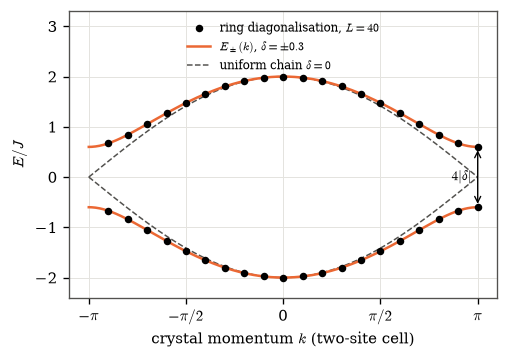

In [11]:
fig, ax = plt.subplots(figsize=(4.6, 3.1))
kk = np.linspace(-np.pi, np.pi, 400)
for band in bloch_bands(kk, 0.0):
    ax.plot(kk, band, "--", color=GRAY, lw=0.9)
for band in bloch_bands(kk, DELTA_EX):
    ax.plot(kk, band, "-", color=COLORS[abs(DELTA_EX)])
# ring eigenvalues, assigned momenta by matching the sorted ring spectrum to the sorted Bloch values
km = 2 * np.pi * np.arange(L_EX // 2) / (L_EX // 2)
km = np.where(km > np.pi, km - 2 * np.pi, km)
order = np.argsort(np.concatenate(bloch_bands(km, DELTA_EX)))
E_ring = np.sort(np.linalg.eigvalsh(hopping_matrix(L_EX, DELTA_EX, periodic=True)))
ax.plot(np.concatenate([km, km])[order], E_ring, "o", color="k", ms=3.5, label=f"ring diagonalisation, $L={L_EX}$")
ax.annotate("", xy=(np.pi, 2 * abs(DELTA_EX)), xytext=(np.pi, -2 * abs(DELTA_EX)),
            arrowprops=dict(arrowstyle="<->", color="k", lw=0.8))
ax.text(np.pi - 0.1, 0, r"$4|\delta|$", ha="right", va="center", fontsize=8)
ax.plot([], [], "-", color=COLORS[abs(DELTA_EX)], label=rf"$E_\pm(k)$, $\delta=\pm{abs(DELTA_EX)}$")
ax.plot([], [], "--", color=GRAY, lw=0.9, label=r"uniform chain $\delta=0$")
ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi], [r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
ax.set_xlabel("crystal momentum $k$ (two-site cell)")
ax.set_ylabel("$E/J$")
ax.set_ylim(-2.4, 3.3)
ax.legend(fontsize=7, loc="upper center")
savefig(fig, "step1_ring_bands")
plt.show()

### 1.7 State selection and $V=0$ benchmarks for later steps

At half filling exactly one of the end pair is occupied. **Convention:** fill the bonding orbital
$\phi_- = (\psi_L - s\,\psi_R)/\sqrt2$ with $s = \mathrm{sgn}\,t = (-1)^{L/2}$ (analytic sign, because the numerical $t$
is pure round-off once the splitting is). With this state:
* $\langle n_j\rangle = 1/2$ on every site (chiral symmetry);
* the edge addition weight $z_0 = |\phi_+(0)|^2/(1-\langle n_0\rangle) = |\psi_L(0)|^2 \simeq 1 - r^2$ (Step 3 anchor at $V=0$).

In [12]:
rows = []
for (L, delta), ep in EDGE.items():
    E, U = ep["E"], ep["U"]
    bulk_filled = [n for n in range(L) if E[n] < 0 and n not in ep["pair"]]
    n0 = np.sum(U[0, bulk_filled] ** 2) + ep["bonding"][0] ** 2
    resolved = abs(split[(split.L == L) & (split.delta == delta)]["eigh/exact - 1"].iloc[0]) < 1e-6
    rows.append({"delta": delta, "L": L, "<n_0>": n0, "z_0": ep["antibonding"][0] ** 2 / (1 - n0),
                 "|psi_L(0)|^2": ep["left"][0] ** 2, "1 - r^2": 1 - ratio(delta) ** 2,
                 "t numeric": ep["t"], "s = (-1)^(L/2)": ep["s"], "splitting resolved by eigh": resolved})
bench = pd.DataFrame(rows).sort_values(["delta", "L"], ascending=[False, True])
display(bench)

res = bench[bench["splitting resolved by eigh"]]
check("sgn(t numeric) = (-1)^(L/2) wherever the splitting is resolved",
      all(np.sign(res["t numeric"]) == res["s = (-1)^(L/2)"]))
check("<n_0> = 1/2", np.max(np.abs(bench["<n_0>"] - 0.5)) < 1e-12, np.max(np.abs(bench["<n_0>"] - 0.5)))
check("z_0 = |psi_L(0)|^2", np.max(np.abs(bench.z_0 - bench["|psi_L(0)|^2"])) < 1e-12)
check("z_0 = 1 - r^2 up to finite size (tol 1e-3)", np.max(np.abs(bench.z_0 - bench["1 - r^2"])) < 1e-3,
      np.max(np.abs(bench.z_0 - bench["1 - r^2"])))

,delta,L,<n_0>,z_0,|psi_L(0)|^2,1 - r^2,t numeric,s = (-1)^(L/2),splitting resolved by eigh
2,-0.15,40,0.5,0.453726,0.453726,0.453686,0.00123565,1,True
5,-0.15,80,0.5,0.453686,0.453686,0.453686,2.92615e-06,1,True
8,-0.15,120,0.5,0.453686,0.453686,0.453686,6.92977e-09,1,True
1,-0.3,40,0.5,0.710059,0.710059,0.710059,3.87553e-06,1,True
4,-0.3,80,0.5,0.710059,0.710059,0.710059,1.62714e-11,1,True
7,-0.3,120,0.5,0.710059,0.710059,0.710059,6.83155e-17,1,False
0,-0.5,40,0.5,0.888889,0.888889,0.888889,3.82396e-10,1,True
3,-0.5,80,0.5,0.888889,0.888889,0.888889,1.0967e-19,1,False
6,-0.5,120,0.5,0.888889,0.888889,0.888889,-3.14531e-29,1,False


[pass] sgn(t numeric) = (-1)^(L/2) wherever the splitting is resolved
[pass] <n_0> = 1/2   [9.99e-16]
[pass] z_0 = |psi_L(0)|^2
[pass] z_0 = 1 - r^2 up to finite size (tol 1e-3)   [3.95e-05]


### 1.8 Lengths with odd $M = L/2$

Every length used above is divisible by 4, so $M$ is even and the sign rule has only been tested with $s = (-1)^{L/2} = +1$.
Here we test $s = -1$ on open chains.
We also test the rings with odd $M$ used in Step 6: $k = \pi$ is not an allowed momentum there, so the gap is $2\min_k E_+(k)$, which is larger than $4|\delta|$.

In [13]:
rows = []
for L in L_ODD_M:
    for delta in [d for d in DELTA_LIST if d < 0]:
        ep = edge_pair(L, delta)
        E, U = ep["E"], ep["U"]
        h = hopping_matrix(L, delta)
        bulk_filled = [n for n in range(L) if E[n] < 0 and n not in ep["pair"]]
        n0 = np.sum(U[0, bulk_filled] ** 2) + ep["bonding"][0] ** 2
        exact = splitting_sturm(L, delta)
        E_vals = np.linalg.eigvalsh(h)
        pair = np.sort(E_vals[np.argsort(np.abs(E_vals))[:2]])
        rows.append({"delta": delta, "L": L, "s = (-1)^(L/2)": ep["s"], "t numeric": ep["t"],
                     "E bonding": ep["bonding"] @ h @ ep["bonding"],
                     "E antibonding": ep["antibonding"] @ h @ ep["antibonding"],
                     "<n_0>": n0, "z_0": ep["antibonding"][0] ** 2 / (1 - n0), "|psi_L(0)|^2": ep["left"][0] ** 2,
                     "dE exact (Sturm)": exact, "asym/exact - 1": splitting_asym(L, delta) / exact - 1,
                     "splitting resolved by eigh": abs((pair[1] - pair[0]) / exact - 1) < 1e-6})
odd = pd.DataFrame(rows).sort_values(["delta", "L"], ascending=[False, True])
display(odd)

res = odd[odd["splitting resolved by eigh"]]
print(f"splitting resolved at {len(res)} of {len(odd)} points")
check("odd M: sgn(t numeric) = (-1)^(L/2) = -1 wherever the splitting is resolved",
      len(res) > 0 and all(np.sign(res["t numeric"]) == res["s = (-1)^(L/2)"]))
check("odd M: bonding orbital lies below antibonding wherever the splitting is resolved",
      all(res["E bonding"] < 0) and all(res["E antibonding"] > 0))
check("odd M: <n_0> = 1/2", np.max(np.abs(odd["<n_0>"] - 0.5)) < 1e-12, np.max(np.abs(odd["<n_0>"] - 0.5)))
check("odd M: z_0 = |psi_L(0)|^2", np.max(np.abs(odd.z_0 - odd["|psi_L(0)|^2"])) < 1e-12,
      np.max(np.abs(odd.z_0 - odd["|psi_L(0)|^2"])))
worst = odd.loc[odd.L >= 40, "asym/exact - 1"].abs().max()
check("odd M: asymptotic formula vs exact splitting (L >= 40, tol 1e-4)", worst < 1e-4, worst)

,delta,L,s = (-1)^(L/2),t numeric,E bonding,E antibonding,<n_0>,z_0,|psi_L(0)|^2,dE exact (Sturm),asym/exact - 1,splitting resolved by eigh
2,-0.15,18,-1,-0.034901,-0.034901,0.034901,0.5,0.46536,0.46536,0.069802,-0.0157508,True
5,-0.15,42,-1,-0.000913289,-0.000913289,0.000913289,0.5,0.453709,0.453709,0.00182658,-2.75191e-05,True
8,-0.15,62,-1,-4.44434e-05,-4.44434e-05,4.44434e-05,0.5,0.453686,0.453686,8.88868e-05,-9.80886e-08,True
11,-0.15,82,-1,-2.16281e-06,-2.16281e-06,2.16281e-06,0.5,0.453686,0.453686,4.32562e-06,-3.10254e-10,True
1,-0.3,18,-1,-0.00351292,-0.00351292,0.00351292,0.5,0.710171,0.710171,0.00702584,-8.83523e-05,True
4,-0.3,42,-1,-2.08683e-06,-2.08683e-06,2.08683e-06,0.5,0.710059,0.710059,4.17365e-06,-7.47293e-11,True
7,-0.3,62,-1,-4.27596e-09,-4.27596e-09,4.27596e-09,0.5,0.710059,0.710059,8.55191e-09,-2.55351e-15,True
10,-0.3,82,-1,-8.76153e-12,-8.76153e-12,8.76153e-12,0.5,0.710059,0.710059,1.75231e-11,-2.77556e-15,True
0,-0.5,18,-1,-6.77404e-05,-6.77404e-05,6.77404e-05,0.5,0.888889,0.888889,0.000135481,-2.03626e-08,True
3,-0.5,42,-1,-1.27465e-10,-1.27465e-10,1.27465e-10,0.5,0.888889,0.888889,2.54931e-10,-1.22125e-15,True


splitting resolved at 10 of 12 points
[pass] odd M: sgn(t numeric) = (-1)^(L/2) = -1 wherever the splitting is resolved
[pass] odd M: bonding orbital lies below antibonding wherever the splitting is resolved
[pass] odd M: <n_0> = 1/2   [8.33e-16]
[pass] odd M: z_0 = |psi_L(0)|^2   [9.99e-16]
[pass] odd M: asymptotic formula vs exact splitting (L >= 40, tol 1e-4)   [2.75e-05]


In [14]:
rows = []
for L in L_RING_ODD:
    k = 2 * np.pi * np.arange(L // 2) / (L // 2)
    for delta in DELTA_LIST:
        E = np.sort(np.linalg.eigvalsh(hopping_matrix(L, delta, periodic=True)))
        Em, Ep = bloch_bands(k, delta)
        rows.append({"L": L, "delta": delta, "max|E - E_bloch|": np.max(np.abs(E - np.sort(np.concatenate([Em, Ep])))),
                     "gap": 2 * E[E > 0].min(), "2 min E_+(k)": 2 * Ep.min(), "4|delta|": 4 * abs(delta)})
ring_odd = pd.DataFrame(rows)
ring_odd["gap / 4|delta|"] = ring_odd.gap / ring_odd["4|delta|"]
display(ring_odd)

check("odd-M ring spectrum = Bloch bands", ring_odd["max|E - E_bloch|"].max() < 1e-12, ring_odd["max|E - E_bloch|"].max())
dev = np.max(np.abs(ring_odd.gap - ring_odd["2 min E_+(k)"]))
check("odd-M ring gap = 2 min E_+(k) over the allowed k", dev < 1e-12, dev)
check("odd-M ring gap > 4|delta| (k = pi is not allowed)", all(ring_odd.gap > ring_odd["4|delta|"]))

,L,delta,max|E - E_bloch|,gap,2 min E_+(k),4|delta|,gap / 4|delta|
0,10,-0.5,6.66134e-16,2.26846,2.26846,2,1.13423
1,10,-0.3,1.22125e-15,1.68237,1.68237,1.2,1.40197
2,10,-0.15,9.99201e-16,1.36143,1.36143,0.6,2.26905
3,10,0.15,4.44089e-16,1.36143,1.36143,0.6,2.26905
4,10,0.3,1.11022e-15,1.68237,1.68237,1.2,1.40197
5,10,0.5,6.66134e-16,2.26846,2.26846,2,1.13423
6,14,-0.5,1.33227e-15,2.14341,2.14341,2,1.0717
7,14,-0.3,8.88178e-16,1.47002,1.47002,1.2,1.22501
8,14,-0.15,1.55431e-15,1.06509,1.06509,0.6,1.77516
9,14,0.15,1.77636e-15,1.06509,1.06509,0.6,1.77516


[pass] odd-M ring spectrum = Bloch bands   [2.22e-15]
[pass] odd-M ring gap = 2 min E_+(k) over the allowed k   [2.22e-15]
[pass] odd-M ring gap > 4|delta| (k = pi is not allowed)


### Step 1 summary

In [15]:
n_pass = sum(c["pass"] for c in CHECKS.values())
print(f"Step 1: {n_pass}/{len(CHECKS)} checks passed")
for name, c in CHECKS.items():
    if not c["pass"]:
        print("  FAILED:", name)

Step 1: 37/37 checks passed


---
## Step 2. Many-body exact diagonalisation (next)